# 07b · Fase 2: TTMn (real/falso) y DLMn (armonía) — correr en Colab

Etapa 7, paso b. Entrena los modelos de la segunda fase sobre los outfits de Polyvore (`fase2_outfits.csv`, partición 70/15/15 sin fuga) y puntúa los outfits de los usuarios para el ranking final (paso d).

| Exp. | Modelo | Qué se prueba |
|---|---|---|
| 2 | XGBoost (tuning con CV) | Clasificador convencional |
| 3 | Random Forest (tuning con CV) | Clasificador convencional |
| **4** | **Red GFS, Opción A** (máscara + signo, pesos aprendidos) | **Propuesta (H1)** |
| 5 | MLP con el mismo nº de parámetros que el 4 | ¿Gana la estructura o el tamaño? |
| 6 | Red GFS con conexiones barajadas (mismos grados) | ¿Importa la conectividad de la mosca? |
| Anexo | Red GFS, Opción B (pesos fijos de neuPrint) | ¿Sirve la biología sin entrenar? |

Todos reciben el mismo vector por outfit (`src/modelo_fly/caracteristicas.py`, 464 columnas). Las redes se entrenan con 3 semillas.

**Cómo correrlo:** Colab → *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*. Luego *Ejecutar todas*. Tarda unos 30–45 min (lo más lento es el tuning del Random Forest). Al final se descarga `etapa7b_resultados.zip`: pégalo en la carpeta del repositorio `modelo-fly` (al lado de `README.md`) y avísame.

In [6]:
import os
import subprocess
import sys
from pathlib import Path

RAMA = "hito3/etapa7-modelos"
URL = "https://github.com/sowiexsker894/Predicci-n-de-compatibilidad-de-outfits-desde-el-conectoma-del-Giant-Fiber-System.git"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    if not Path("/content/modelo-fly").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", RAMA, URL, "/content/modelo-fly"], check=True)
    ROOT = Path("/content/modelo-fly")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(ROOT / "src"))
try:
    import xgboost
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
    import xgboost
import torch
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("Repositorio:", ROOT, "| torch", torch.__version__, "| xgboost", xgboost.__version__, "| dispositivo:", DISPOSITIVO)

Repositorio: /content/modelo-fly | torch 2.14.1+cu130 | xgboost 3.4.1 | dispositivo: cuda


In [7]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import randint, uniform
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, roc_auc_score
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, StratifiedGroupKFold
from xgboost import XGBClassifier, XGBRegressor

from modelo_fly.caracteristicas import COLUMNAS, codificar
from modelo_fly.conectoma import barajar_conexiones, matrices, neuronas
from modelo_fly.redes import MLP, RedGFS, ancho_mlp, entrenar, parametros, predecir
from modelo_fly.usuarios import cargar_items

PROC = ROOT / "data" / "processed" / "hito3"
SALIDA = ROOT / "salida_7b"
SALIDA.mkdir(exist_ok=True)
SEMILLAS = [0, 1, 2]
t0 = time.time()

## 1. Datos

In [8]:
items, atrib, outfits = cargar_items(PROC)
X = codificar(outfits["ids"].tolist(), atrib)
parte = {p: (outfits["particion"] == p).to_numpy() for p in ["train", "valid", "test"]}
y_real = outfits["real"].to_numpy()
y_score = outfits["score"].to_numpy().astype(float)
grupos = outfits["set_id_origen"].to_numpy()
print("Matriz:", X.shape, {p: int(m.sum()) for p, m in parte.items()})

# Outfits de los usuarios (historial + candidatos del paso a) que se puntúan para el ranking.
historial = pd.read_csv(PROC / "historial.csv")
cand = pd.read_csv(PROC / "candidatos.csv")
usuarios_out = (pd.concat([historial[["outfit_id", "item_ids"]], cand[["outfit_id", "item_ids"]]])
                .drop_duplicates("outfit_id").reset_index(drop=True))
X_usu = codificar(usuarios_out["item_ids"].str.split("|").tolist(), atrib)
print("Outfits de usuarios a puntuar:", len(usuarios_out))

Matriz: (45036, 464) {'train': 31875, 'valid': 6582, 'test': 6579}
Outfits de usuarios a puntuar: 64750


In [9]:
nodes = pd.read_csv(PROC / "gfs_nodes.csv")
edges = pd.read_csv(PROC / "gfs_edges.csv")
tabla = neuronas(nodes)
conteo, mascara, _ = matrices(tabla, edges)
signo = tabla["signo"].to_numpy()
IDX = {"entrada": tabla.index[tabla["capa"] == "entrada"].to_numpy(),
       "ttmn": tabla.index[tabla["type"] == "TTMn"].to_numpy(),
       "dlmn": tabla.index[tabla["type"].str.startswith("DLMn")].to_numpy()}
print({k: len(v) for k, v in IDX.items()}, "| conexiones:", int(mascara.sum()))

{'entrada': 311, 'ttmn': 2, 'dlmn': 10} | conexiones: 20684


## 2. Árboles con tuning (experimentos 2 y 3)

Búsqueda aleatoria de hiperparámetros con validación cruzada de 5 folds **dentro de train**, agrupando por outfit de origen (un real y sus negativos van siempre al mismo fold). TTMn se optimiza por AUC y DLMn por MAE.

In [10]:
Xtr, gtr = X[parte["train"]], grupos[parte["train"]]
cv_clf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=2026)
cv_reg = GroupKFold(n_splits=5)
gpu_xgb = {"device": "cuda"} if DISPOSITIVO == "cuda" else {"n_jobs": -1}
ESPACIOS = {
    "xgboost": (lambda: XGBClassifier(tree_method="hist", eval_metric="logloss", random_state=0, **gpu_xgb),
                lambda: XGBRegressor(tree_method="hist", random_state=0, **gpu_xgb),
                {"n_estimators": randint(200, 900), "max_depth": randint(3, 9), "learning_rate": uniform(0.02, 0.15),
                 "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.4, 0.5), "min_child_weight": randint(1, 10)},
                10),
    "random_forest": (lambda: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0),
                      lambda: RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0),
                      {"max_depth": [None, 20, 40], "min_samples_leaf": [1, 3, 10],
                       "max_features": ["sqrt", 0.2], "max_samples": [0.5, None]},
                      4),
}
arboles, mejores = {}, {}
for nombre, (clf, reg, espacio, n_iter) in ESPACIOS.items():
    t = time.time()
    b_clf = RandomizedSearchCV(clf(), espacio, n_iter=n_iter, scoring="roc_auc", cv=cv_clf, random_state=0,
                               n_jobs=1, refit=True).fit(Xtr, y_real[parte["train"]], groups=gtr)
    b_reg = RandomizedSearchCV(reg(), espacio, n_iter=n_iter, scoring="neg_mean_absolute_error", cv=cv_reg,
                               random_state=0, n_jobs=1, refit=True).fit(Xtr, y_score[parte["train"]], groups=gtr)
    arboles[nombre] = (b_clf.best_estimator_, b_reg.best_estimator_)
    mejores[nombre] = {"ttmn": {k: (v.item() if hasattr(v, "item") else v) for k, v in b_clf.best_params_.items()},
                       "dlmn": {k: (v.item() if hasattr(v, "item") else v) for k, v in b_reg.best_params_.items()},
                       "auc_cv": round(b_clf.best_score_, 4), "mae_cv": round(-b_reg.best_score_, 4)}
    print(f"{nombre}: AUC CV {b_clf.best_score_:.3f} | MAE CV {-b_reg.best_score_:.3f} | {time.time() - t:.0f} s")
(SALIDA / "fase2_hiperparametros.json").write_text(json.dumps(mejores, indent=2, default=str), encoding="utf-8")

xgboost: AUC CV 0.645 | MAE CV 0.174 | 166 s
random_forest: AUC CV 0.634 | MAE CV 0.169 | 669 s


837

## 3. Redes (experimentos 4, 5, 6 y anexo)

Mismo entrenamiento para todas: AdamW, lotes de 512, hasta 40 épocas con parada temprana en validación (paciencia 5). Pérdida = BCE(TTMn) + MSE(DLMn/7).

In [11]:
def red(variante, semilla):
    if variante == "gfs_a":
        return RedGFS(X.shape[1], conteo, signo, IDX["entrada"], IDX["ttmn"], IDX["dlmn"])
    if variante == "gfs_b":
        return RedGFS(X.shape[1], conteo, signo, IDX["entrada"], IDX["ttmn"], IDX["dlmn"], entrenar_pesos=False)
    if variante == "gfs_barajada":
        c, _ = barajar_conexiones(tabla, edges, semilla=semilla)
        return RedGFS(X.shape[1], c, signo, IDX["entrada"], IDX["ttmn"], IDX["dlmn"])
    if variante == "mlp":
        return MLP(X.shape[1], ancho_mlp(X.shape[1], parametros(red("gfs_a", semilla))))

VARIANTES = ["gfs_a", "mlp", "gfs_barajada", "gfs_b"]
print({v: parametros(red(v, 0)) for v in VARIANTES}, "| ancho del MLP:", ancho_mlp(X.shape[1], parametros(red("gfs_a", 0))))

redes, curvas = {}, {}
tr, va = parte["train"], parte["valid"]
for v in VARIANTES:
    for s in SEMILLAS:
        t = time.time()
        m = red(v, s)
        curvas[(v, s)] = entrenar(m, X[tr], y_real[tr], y_score[tr], X[va], y_real[va], y_score[va],
                                  semilla=s, dispositivo=DISPOSITIVO)
        redes[(v, s)] = m
        print(f"{v} semilla {s}: {len(curvas[(v, s)])} épocas, pérdida valid {min(curvas[(v, s)]):.4f}, {time.time() - t:.0f} s")

{'gfs_a': 165640, 'mlp': 165207, 'gfs_barajada': 165640, 'gfs_b': 144956} | ancho del MLP: 235
gfs_a semilla 0: 22 épocas, pérdida valid 0.6438, 12 s
gfs_a semilla 1: 31 épocas, pérdida valid 0.6352, 7 s
gfs_a semilla 2: 25 épocas, pérdida valid 0.6428, 6 s
mlp semilla 0: 15 épocas, pérdida valid 0.6262, 2 s
mlp semilla 1: 15 épocas, pérdida valid 0.6238, 2 s
mlp semilla 2: 15 épocas, pérdida valid 0.6201, 2 s
gfs_barajada semilla 0: 40 épocas, pérdida valid 0.6371, 12 s
gfs_barajada semilla 1: 12 épocas, pérdida valid 0.6414, 6 s
gfs_barajada semilla 2: 10 épocas, pérdida valid 0.6419, 5 s
gfs_b semilla 0: 40 épocas, pérdida valid 0.6391, 9 s
gfs_b semilla 1: 27 épocas, pérdida valid 0.6397, 5 s
gfs_b semilla 2: 25 épocas, pérdida valid 0.6434, 6 s


## 4. Resultados en test (fase 2)

In [12]:
EXPERIMENTO = {"xgboost": "2", "random_forest": "3", "gfs_a": "4", "mlp": "5", "gfs_barajada": "6", "gfs_b": "anexo"}
te = parte["test"]
tipo_te = outfits.loc[te, "tipo"].to_numpy()
pred_test = pd.DataFrame({"outfit_id": outfits.loc[te, "outfit_id"].to_numpy(), "tipo": tipo_te,
                          "real": y_real[te], "score": y_score[te]})
pred_usu = usuarios_out[["outfit_id"]].copy()

def puntuar(nombre, semilla, p_te, s_te, p_usu, s_usu, n_param):
    col = f"{nombre}_s{semilla}"
    pred_test[f"{col}_ttmn"], pred_test[f"{col}_dlmn"] = p_te.round(5), s_te.round(4)
    pred_usu[f"{col}_ttmn"], pred_usu[f"{col}_dlmn"] = p_usu.round(5), s_usu.round(4)
    fila = {"modelo": nombre, "experimento": EXPERIMENTO[nombre], "semilla": semilla, "parametros": n_param,
            "AUC_TTMn": roc_auc_score(y_real[te], p_te)}
    for t in ["aleatorio", "dificil"]:
        m = np.isin(tipo_te, ["real", t])
        fila[f"AUC_TTMn_{t}"] = roc_auc_score(y_real[te][m], p_te[m])
    fila["MAE_DLMn"] = mean_absolute_error(y_score[te], np.clip(s_te, 0, 7))
    return fila

filas = []
for nombre, (clf, reg) in arboles.items():
    filas.append(puntuar(nombre, 0, clf.predict_proba(X[te])[:, 1], reg.predict(X[te]),
                         clf.predict_proba(X_usu)[:, 1], reg.predict(X_usu), np.nan))
for (v, s), m in redes.items():
    p_te, s_te = predecir(m, X[te], DISPOSITIVO)
    p_u, s_u = predecir(m, X_usu, DISPOSITIVO)
    filas.append(puntuar(v, s, p_te, s_te, p_u, s_u, parametros(m)))
metricas = pd.DataFrame(filas)
base = {"MAE siempre 7": mean_absolute_error(y_score[te], np.full(te.sum(), 7.0)),
        "MAE media de train": mean_absolute_error(y_score[te], np.full(te.sum(), y_score[tr].mean()))}
print({k: round(v, 3) for k, v in base.items()})
resumen = (metricas.groupby(["experimento", "modelo"], sort=False)
           [["AUC_TTMn", "AUC_TTMn_aleatorio", "AUC_TTMn_dificil", "MAE_DLMn"]].agg(["mean", "std"]).round(4))
display(resumen)

{'MAE siempre 7': 0.307, 'MAE media de train': 0.434}


AUC_TTMn         AUC_TTMn_aleatorio          \
                              mean     std               mean     std   
experimento modelo                                                      
2           xgboost         0.6396     NaN             0.7142     NaN   
3           random_forest   0.6233     NaN             0.6912     NaN   
4           gfs_a           0.5319  0.0441             0.5424  0.0777   
5           mlp             0.6298  0.0054             0.6997  0.0074   
6           gfs_barajada    0.5244  0.0350             0.5311  0.0617   
anexo       gfs_b           0.5340  0.0266             0.5499  0.0465   

                          AUC_TTMn_dificil         MAE_DLMn          
                                      mean     std     mean     std  
experimento modelo                                                   
2           xgboost                 0.5649     NaN   0.1795     NaN  
3           random_forest           0.5553     NaN   0.1900     NaN  
4           gfs_a                   0.5214  0.0111   0.3488  0.0582  
5           mlp                     0.5598  0.0034   0.2783  0.0173  
6           gfs_barajada            0.5177  0.0084   0.3160  0.0090  
anexo       gfs_b                   0.5182  0.0066   0.3573  0.0533

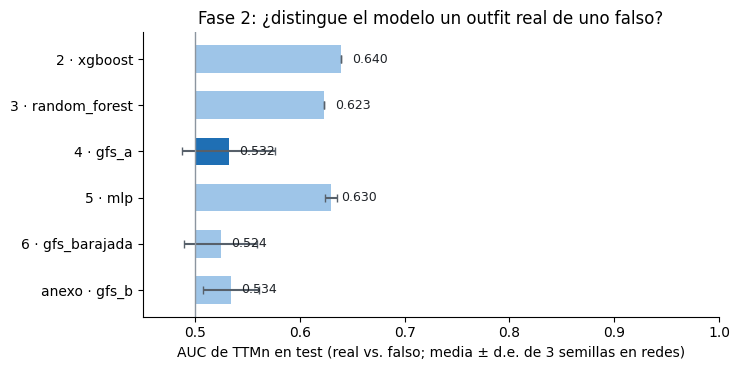

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
orden = ["xgboost", "random_forest", "gfs_a", "mlp", "gfs_barajada", "gfs_b"]
g = metricas.groupby("modelo")["AUC_TTMn"].agg(["mean", "std"]).reindex(orden)
colores = ["#9ec5e8", "#9ec5e8", "#1f6fb4", "#9ec5e8", "#9ec5e8", "#9ec5e8"]
ax.barh(range(len(orden))[::-1], g["mean"] - 0.5, left=0.5, xerr=g["std"].fillna(0), color=colores, height=0.6,
        error_kw={"ecolor": "#57606a", "capsize": 3})
ax.set_yticks(range(len(orden))[::-1], [f"{EXPERIMENTO[m]} · {m}" for m in orden])
for y, v in zip(range(len(orden))[::-1], g["mean"]):
    ax.text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=9, color="#1f2328")
ax.axvline(0.5, color="#8c959f", lw=1)
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("AUC de TTMn en test (real vs. falso; media ± d.e. de 3 semillas en redes)")
ax.set_title("Fase 2: ¿distingue el modelo un outfit real de uno falso?")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(SALIDA / "fig_fase2_auc.png", dpi=150)
plt.show()

## 5. Guardar y descargar

In [14]:
metricas.round(5).to_csv(SALIDA / "fase2_metricas.csv", index=False)
pred_test.to_csv(SALIDA / "fase2_pred_test.csv.gz", index=False)
pred_usu.to_csv(SALIDA / "fase2_pred_usuarios.csv.gz", index=False)
pd.DataFrame([{"modelo": v, "semilla": s, "epocas": len(c), "perdida_valid_min": min(c)} for (v, s), c in curvas.items()]
             ).to_csv(SALIDA / "fase2_curvas.csv", index=False)
(SALIDA / "fase2_meta.json").write_text(json.dumps({
    "rama": RAMA, "dispositivo": DISPOSITIVO, "torch": torch.__version__, "xgboost": xgboost.__version__,
    "n_columnas": len(COLUMNAS), "semillas": SEMILLAS, "baselines_dlmn": base,
    "minutos": round((time.time() - t0) / 60, 1)}, indent=2), encoding="utf-8")
import shutil
zip_path = shutil.make_archive(str(ROOT / "etapa7b_resultados"), "zip", SALIDA)
print("Listo en", round((time.time() - t0) / 60, 1), "min:", zip_path)
if EN_COLAB:
    from google.colab import files
    files.download(zip_path)

Listo en 18.2 min: /content/modelo-fly/etapa7b_resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>